# Entanglement-assisted Hamiltonian dynamics learning: a guided tutorial

This notebook shows how to obtain the main results of

> A. Usui, G. Abad-López, H. SV, A. Sanpera, S. S. Bhattacharya, *Entanglement-assisted Hamiltonian dynamics
> learning* (2026), [arXiv:2602.15931](https://arxiv.org/abs/2602.15931) (figure and section numbers of v2)

with the code of this repository, the way a user would run it: every training is configured through the `CFG` object
of [`src/config.py`](src/config.py) and run by the same functions that `python src/main.py` calls.

| § | What it shows | Paper |
|---|---|---|
| 1 | The task, the targets and the generator circuits, with and without the auxiliary qubit | Sec. II–III, Figs. 1 and 2(a) |
| 2 | **Inserting the auxiliary qubit at a plateau**, midway through training: connectivity and initialisation | Sec. III A–C, Fig. 2(b) |
| 3 | **Timing**: the auxiliary qubit present from the start instead | Sec. III B, Fig. 3 |
| 4 | **Entanglement** during training: entropy of the auxiliary qubit and pairwise negativities | Sec. IV A, Fig. 5 |
| 5 | **Gradients** of the cost at the insertion and 500 iterations later | Sec. IV B, Fig. 6 |
| 6 | Four system qubits (optional, the slowest) | Appendix D, Fig. 8 |
| 7 | Where to go from here: the other results and the matching `CFG` options | — |

**A tutorial, not an exact replica.** Every experiment here uses settings similar to the paper's, but not identical:
fewer trainings per setting, other random draws, and smaller studies of the entanglement and
the gradients. Read it as a guide to obtaining such results with the library. Each section shows the paper's values
next to ours for orientation; expect the same trends, not the same numbers.

**Branch: this is the version for `main`.** This notebook runs on the `main` branch, with its original NumPy code.
**The outputs saved in it were generated with the `pennylane-claude` branch** (PennyLane and PyTorch), whose version of
this notebook is the same tutorial: sections 2–6 show the results of that branch, with `N_RUNS = 50`,
`ITERATIONS = 3000` and `N_ENTANGLEMENT = 24`. The setup and section 1 show this branch's code. The paths that the
saved outputs print are those of `pennylane-claude` (`generated_data/notebook/`); this version saves its results to
`generated_data/notebook_main/`, so that the two branches never read each other's saved models.

**Runtime.** The NumPy code of this branch trains one run at a time, roughly a hundred times slower than the batched
code of `pennylane-claude`: one training of 3000 iterations takes about 3–10 minutes. The first cell is therefore set
to a small demonstration (2 runs per setting, 300 iterations), which runs §1–5 in roughly 1.5 hours; the settings of
the saved outputs would take more than a week here. Every result is saved in `generated_data/notebook_main/` and
reused when the notebook runs again, also after an interruption (set `RERUN = True` to train again).

**Requirements.** The environment of the README (`pip install -r requirements.txt`) plus Jupyter
(`pip install jupyter`).

## Before you start: how the code is meant to run

The code is a command-line program, not a library written for notebooks. The usual workflow is to edit the settings in
[`src/config.py`](src/config.py) and run [`src/main.py`](src/main.py) from the repository root:

```bash
# 1. Choose the experiment: edit the fields of the Config class in src/config.py, for example
#      system_size = 3, custom_hamiltonian_terms = ["ZZZ"], gen_layers = 3,
#      common_initial_plateaus = True, N_initial_plateaus = 50, reps_new_config = [...]
# 2. Train (every run is saved to generated_data/<timestamp>/):
python src/main.py

# 3. Replot a finished multiple run with your own labels: edit the top of src/replot.py, for example
#      time_stamp_to_replot = "notebook_main/mid_ZZZ"   # a folder of generated_data/: the runs of section 2
#      x_label = "auxiliary qubit inserted"
#      run_names = ["(a1) random", "(a2) random", "(a3) random", "(a4) random",
#                   "(a1) zero", "(a2) zero", "(a3) zero", "(a4) zero"]   # one per entry of reps_new_config
python src/replot.py       # writes the summary plots into that folder
```

### Running the code from a notebook

The code expects to be run as `python src/main.py`, so driving it from a notebook needs a few adjustments. The
helper cells below make all of them: you can skip this on a first read.

<details>
<summary><b>What the helper cells take care of</b> (click to expand)</summary>

- **One global `CFG`.** Its changes persist from cell to cell, so every experiment rebuilds it from the base settings
  with `configure()`.
- **Working folder.** Results are written relative to it; the setup cell moves to the repository root.
- **Plots.** The code draws to files (matplotlib's `Agg` backend) and changes matplotlib's style while plotting; the
  setup cell restores inline figures, and the notebook sets its style again after every training.
- **Errors.** `run_multiple_trainings()` logs errors instead of raising them; the notebook checks the log and stops.
- **Saved results.** Each experiment is reused from `generated_data/notebook_main/<name>/`. Changing a setting of the first
  cell deletes and retrains the experiments it affects: move that folder aside first to keep them.
- **Speed.** The setup cell sets one thread for NumPy's linear algebra, about three times faster for the small
  matrices of this code (it applies only if the kernel has not imported NumPy yet).
- **Internals.** Section 5 uses the generator's analytic gradient, `Generator._grad_theta()`, an internal method.

</details>

## 0. Setup

Choose what to run in the first cell below. The cell after it is plumbing (finding the repository, importing `src/`,
one thread for NumPy, the matplotlib settings) and is collapsed: click its bar to expand it. The third cell imports the parts of the code
that the notebook uses.

In [1]:
# -- What to run --------------------------------------------------------------------------------------------------------
# A small demonstration, for the slow NumPy code of this branch (roughly 1.5 hours for sections 1-5). The outputs saved
# in this notebook come from the pennylane-claude branch with N_RUNS = 50, ITERATIONS = 3000, N_ENTANGLEMENT = 24 and
# GRADIENT_ITERATIONS = 500 (the paper: 100 trainings per setting, 3000 iterations before the insertion and 3000 after).
N_RUNS = 2                 # trainings (plateaus) per setting
ITERATIONS = 300           # iterations before the insertion, and after it (a multiple of 300)
SEED = 2026                # numpy seed, set before each experiment (initial angles and critics)
RERUN = False              # False: reuse the results that an earlier execution of this notebook saved
RUN_N4 = False             # section 6, four system qubits: roughly 4-5 hours more with these settings
N_ENTANGLEMENT = 2         # plateaus of section 4 (entanglement diagnostics along the training)
GRADIENT_ITERATIONS = 50   # section 5: the gradients at the insertion and this many iterations later (the paper: 500)

In [2]:
# Setup plumbing: work from the repository root (the runs are saved to ./generated_data, as with `python src/main.py`),
# import the code in src/ as main.py does, and show the figures inline
import contextlib, copy, json, os, shutil, sys, time
from pathlib import Path

# One thread for NumPy's linear algebra: faster for the small matrices of this code (only before NumPy is imported)
for _var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_var, "1")

ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "config.py").exists():
    if ROOT.parent == ROOT:
        raise RuntimeError("Open this notebook from inside the qgan_subspace repository.")
    ROOT = ROOT.parent
if not (ROOT / "src" / "tools" / "qobjects" / "qcircuit.py").exists():
    raise RuntimeError("This version of the notebook is for the NumPy code of the main branch. On the "
                       "pennylane-claude branch, use that branch's tutorial.ipynb.")
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt, numpy as np, scipy
import tools.plot_hub  # (the code's plotting module: it selects matplotlib's file-only "Agg" backend when imported)

%matplotlib inline
# (the training's own plots change these globally, so run_experiment() sets them again after every training)
STYLE = {"axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "font.family": "sans-serif",
         "axes.labelsize": 10, "legend.fontsize": 8, "figure.figsize": (6.4, 4.8), "figure.dpi": 100, "savefig.dpi": 100}
plt.rcParams.update(STYLE)
assert ITERATIONS % 300 == 0, "ITERATIONS must be a multiple of 300 (the epoch length)"

In [3]:
# The parts of the code used below: the configuration, what `python src/main.py` runs, and (sections 1 and 5) internals
from config import CFG
from tools.training_init import run_multiple_trainings
from qgan.target import get_target_unitary
from qgan.generator import Ansatz
from tools.qobjects.qcircuit import QuantumCircuit
from qgan.training import Training
from tools.data.loading_helpers import load_models_if_specified
from qgan.cost_functions import compute_fidelity

print("repository:", ROOT.name)
print(f"numpy {np.__version__}, scipy {scipy.__version__}, threads: {os.environ.get('OMP_NUM_THREADS')}")

repository: qgan_subspace
numpy 2.5.4, scipy 1.18.1, threads: 1


### The base configuration

Every option of the code is a field of `CFG`, documented in `src/config.py`. On this branch `CFG` has no `update()`
method: `configure()` below sets the fields one by one, checks that each one exists, and recomputes the results
paths. The notebook starts every experiment from the settings of the
paper, listed below, so edits to the defaults in `src/config.py` do not change its results. Only the fields that
differ between the experiments change from one to the next.

In [4]:
BASE = dict(
    system_size=3, target_hamiltonian="custom_h", custom_hamiltonian_terms=["ZZZ"],     # target: H_T = Z1Z2Z3, t = 1
    custom_hamiltonian_strengths=[1.0], time_to_evolve=1.0,
    gen_layers=3, gen_ansatz="ZZ_Z_X",                                                  # generator (Fig. 1(b))
    extra_ancilla=False, ancilla_topology="bridge", ancilla_connect_to=None,            # auxiliary qubit: off here
    do_ancilla_1q_gates=True, start_ancilla_gates_randomly=True,
    dis_module_cap="auto",                                                              # critic
    l_rate=0.01, momentum_coeff=0.9, steps_dis=1, steps_gen=1,                          # optimiser (Appendix A 5)
    epochs=ITERATIONS // 300, iterations_epoch=300, max_fidelity=0.99,                  # training
    compute_and_save_fid_every_x_iter=10, log_every_x_iter=300,
    compute_entanglement=False,                                                         # off here (section 4)
    load_timestamp=None, type_of_warm_start="none",                                     # continuing a saved run
    run_multiple_experiments=True,
)


def configure(**changes):
    # CFG = the notebook's base configuration, then `changes`, set field by field
    for key, value in {**BASE, **changes}.items():
        if not hasattr(CFG, key):
            raise AttributeError(f"CFG has no field {key!r} on this branch")
        setattr(CFG, key, copy.deepcopy(value))
    CFG.base_data_path = f"./generated_data/{CFG.run_timestamp}"
    CFG.set_results_paths()


configure()
# The resulting configuration, as printed at the top of every run's logs/log.txt (output collapsed)
print(CFG.show_data())

run_timestamp: 2026-11-10__21-12-29,
----------------------------------------------
load_timestamp: None,
type_of_warm_start: none,
warm_start_strength: 0.1,
----------------------------------------------
system_size: 3,
extra_ancilla: False,
ancilla_topology: bridge,
ancilla_connect_to: None,
do_ancilla_1q_gates: True,
start_ancilla_gates_randomly: True,
----------------------------------------------
gen_layers: 3,
gen_ansatz: ZZ_Z_X,
----------------------------------------------
time_to_evolve: 1.0,
target_hamiltonian: custom_h,
custom_hamiltonian_terms: ['ZZZ'],
custom_hamiltonian_strengths: [1.0],
----------------------------------------------
epochs: 1,
iterations_epoch: 300,
log_every_x_iter: 300,
compute_and_save_fid_every_x_iter: 10,
max_fidelity: 0.99,
compute_entanglement: False,
steps_dis: 1,
steps_gen: 1,
----------------------------------------------
l_rate: 0.01,
momentum_coeff: 0.9,
dis_module_cap: auto (60),



## 1. The task, the targets and the circuits

**The task** (Sec. II). The generator learns a unitary $U_T$ through its Choi state: a copy $A$ of the system $B$ is
maximally entangled with it, $|\Omega\rangle = d^{-1/2}\sum_i |i\rangle_A|i\rangle_B$, and the fidelity of the
generator's output with the target's is
$$F = |\langle\Omega|(\mathbb I_A\otimes U_G)^\dagger(\mathbb I_A\otimes U_T)|\Omega\rangle|^2
= |\mathrm{Tr}(U_G^\dagger U_T)|^2/d^2 .$$
The critic and the generator play the minimax game of the quantum Wasserstein GAN (Appendix A). The figure of merit of
a training is the largest fidelity it reaches, $F_{\max}$, averaged over the runs: $F^{\mathrm{avg}}_{\max}$ (Eq. 5).

**The targets** (Sec. III): the unit-time evolution of $H_T = Z_1Z_2Z_3$ and of $H_T = Z_1Z_2Z_3 + X_1X_2X_3/4$
(non-commuting terms). In `CFG`: `custom_hamiltonian_terms=["ZZZ"]` (or `["ZZZ", "XXX"]`) with
`custom_hamiltonian_strengths=[1]` (or `[1, 0.25]`), and `time_to_evolve=1`.

In [5]:
TARGETS = {
    "ZZZ":         dict(custom_hamiltonian_terms=["ZZZ"], custom_hamiltonian_strengths=[1.0]),
    "ZZZ + XXX/4": dict(custom_hamiltonian_terms=["ZZZ", "XXX"], custom_hamiltonian_strengths=[1.0, 0.25]),
}
Z = np.diag([1.0, -1.0])
for name, target in TARGETS.items():
    configure(**target)
    U_T = np.asarray(get_target_unitary(CFG.target_hamiltonian, CFG.system_size))
    print(f"{name:12s} U_T is {U_T.shape} and unitary: {np.allclose(U_T.conj().T @ U_T, np.eye(8))}")

# For H_T = ZZZ, exp(-i ZZZ) = cos(1) I - i sin(1) ZZZ (Sec. IV A)
configure(**TARGETS["ZZZ"])
ZZZ = np.kron(np.kron(Z, Z), Z)
U_T = np.asarray(get_target_unitary(CFG.target_hamiltonian, CFG.system_size))
print("exp(-i ZZZ) = cos(1) I - i sin(1) ZZZ:", np.allclose(U_T, np.cos(1) * np.eye(8) - 1j * np.sin(1) * ZZZ))
print(f"GME threshold of the target (Sec. IV A): F > sin^2(1) = {np.sin(1) ** 2:.4f}")

ZZZ          U_T is (8, 8) and unitary: True
ZZZ + XXX/4  U_T is (8, 8) and unitary: True
exp(-i ZZZ) = cos(1) I - i sin(1) ZZZ: True
GME threshold of the target (Sec. IV A): F > sin^2(1) = 0.7081


**The circuits** (Fig. 1(b) and 2(a)). Each layer of the generator applies $R_X$ and $R_Z$ to every system qubit and
$R_{ZZ}$ between neighbouring qubits of the chain. The auxiliary qubit $a$ (the *ancilla* in the code) starts in
$|0\rangle$, receives its own $R_X$ and $R_Z$, and couples to the system through $R_{ZZ}$ gates. The four
configurations of the paper are the topologies of `CFG`:

| paper | the auxiliary qubit couples to | in `CFG` |
|---|---|---|
| — | (no auxiliary qubit) | `extra_ancilla=False` |
| (a1) | one qubit, the end of the chain | `extra_ancilla=True, ancilla_topology="ansatz"` |
| (a2) | two neighbouring qubits | `extra_ancilla=True, ancilla_topology="bridge", ancilla_connect_to=1` |
| (a3) | the two qubits at the ends of the chain | `extra_ancilla=True, ancilla_topology="bridge"` |
| (a4) | every system qubit | `extra_ancilla=True, ancilla_topology="total"` |

The cell below draws one layer of each. Wires 3–5 are the system qubits and wire 6 is the auxiliary qubit; wires
0–2 hold the reference copy $A$ of the Choi state, on which the generator does not act.

In [6]:
ARCHS = {
    "no aux. qubit": dict(extra_ancilla=False),
    "(a1)": dict(extra_ancilla=True, ancilla_topology="ansatz", ancilla_connect_to=None),
    "(a2)": dict(extra_ancilla=True, ancilla_topology="bridge", ancilla_connect_to=1),
    "(a3)": dict(extra_ancilla=True, ancilla_topology="bridge", ancilla_connect_to=None),
    "(a4)": dict(extra_ancilla=True, ancilla_topology="total", ancilla_connect_to=None),
}
GATE_NAMES = {"X": "RX", "Z": "RZ", "ZZ": "RZZ"}


def layer_gates(arch):
    # The gates of one generator layer (without the Choi-state preparation), in the order the code applies them
    configure(gen_layers=1, **ARCHS[arch])
    size = CFG.system_size + (1 if CFG.extra_ancilla else 0)
    circuit = Ansatz.get_ansatz_type_circuit(CFG.gen_ansatz)(QuantumCircuit(size, "generator"), size, 1)
    label = lambda q: "a" if CFG.extra_ancilla and q == CFG.system_size else str(q + 1)  # qubits 1-3, a: auxiliary
    return [f"{GATE_NAMES[g.name]}({label(g.qubit1)}" + (f",{label(g.qubit2)})" if g.qubit2 is not None else ")")
            for g in circuit.gates]


for arch in ARCHS:
    gates = layer_gates(arch)  # (leaves CFG at 1 layer; every experiment below sets it again)
    print(f"── {arch}: {len(gates)} gates per layer, {3 * len(gates)} parameters in 3 layers")
    print("   " + " ".join(gates), "\n")

── no aux. qubit: 8 gates per layer, 24 parameters in 3 layers
   RX(1) RZ(1) RX(2) RZ(2) RX(3) RZ(3) RZZ(1,2) RZZ(2,3) 

── (a1): 11 gates per layer, 33 parameters in 3 layers
   RX(1) RZ(1) RX(2) RZ(2) RX(3) RZ(3) RX(a) RZ(a) RZZ(1,2) RZZ(2,3) RZZ(3,a) 

── (a2): 12 gates per layer, 36 parameters in 3 layers
   RX(1) RZ(1) RX(2) RZ(2) RX(3) RZ(3) RX(a) RZ(a) RZZ(1,2) RZZ(2,3) RZZ(1,a) RZZ(2,a) 

── (a3): 12 gates per layer, 36 parameters in 3 layers
   RX(1) RZ(1) RX(2) RZ(2) RX(3) RZ(3) RX(a) RZ(a) RZZ(1,2) RZZ(2,3) RZZ(1,a) RZZ(3,a) 

── (a4): 13 gates per layer, 39 parameters in 3 layers
   RX(1) RZ(1) RX(2) RZ(2) RX(3) RZ(3) RX(a) RZ(a) RZZ(1,2) RZZ(2,3) RZZ(1,a) RZZ(2,a) RZZ(3,a) 



With three layers the circuits have 24, 33, 36, 36 and 39 parameters (Appendix B: 33, 36, 36 and 39 for (a1)–(a4)).
(a2) and (a3) have the same number of gates; they differ only in which qubits the auxiliary qubit connects.

## 2. Inserting the auxiliary qubit at a plateau

The protocol of Sec. III. The generator without auxiliary qubit is trained for 3000 iterations. The trainings that do
not reach $F = 0.99$, the *plateaus*, are continued for 3000 more: once unchanged (the **control**), and once with each
auxiliary-qubit configuration inserted, its angles either random (green in Fig. 2(b)) or zero (brown). The repository
runs this protocol with `CFG.common_initial_plateaus = True`:

1. `CFG.N_initial_plateaus` trainings of the base circuit are run, and only those that stay below
   `CFG.max_fidelity` are kept (the others are replaced by new ones).
2. Each plateau is continued with each entry of `CFG.reps_new_config`, a dict of `CFG` changes. The continuation loads
   the saved generator and critic (`CFG.load_timestamp`). The inserted gates get random angles, or zero with
   `start_ancilla_gates_randomly=False`; the critic gets a new random row for the auxiliary qubit.

The helper below sets `CFG` and calls `run_multiple_trainings()`, as `python src/main.py` does with
`CFG.run_multiple_experiments = True`, with its output redirected to a file. Its results go to
`generated_data/notebook_main/<name>/`.

In [7]:
RESULTS = "notebook_main"  # this branch's results folder in generated_data/ (pennylane-claude uses notebook/)


def run_experiment(name, settings, from_plateaus=False, n_runs=N_RUNS, **changes):
    # Train `settings` ({label: CFG changes}) with run_multiple_trainings(), in generated_data/<RESULTS>/<name>.
    # From plateaus: n_runs plateaus, each continued unchanged (the control) and with each setting.
    # From scratch: n_runs trainings of each setting. Reuses a finished folder unless RERUN.
    folder = Path("generated_data") / RESULTS / name
    signature = dict(settings=settings, from_plateaus=from_plateaus, n_runs=n_runs, iterations=ITERATIONS, seed=SEED,
                     changes=changes)
    marker = folder / "notebook_signature.json"
    runtime = folder / "notebook_runtime.txt"
    if not RERUN and marker.exists() and json.loads(marker.read_text()) == json.loads(json.dumps(signature)):
        took = f" (trained in {float(runtime.read_text()):.1f} min)" if runtime.exists() else ""
        print(f"{name}: reusing the results saved in {folder}/{took}")
        return folder
    shutil.rmtree(folder, ignore_errors=True)
    folder.mkdir(parents=True)
    configure(run_timestamp=f"{RESULTS}/{name}", common_initial_plateaus=from_plateaus, N_reps_if_from_scratch=n_runs,
              N_initial_plateaus=n_runs, N_reps_each_init_plateau=1, reps_new_config=list(settings.values()), **changes)
    np.random.seed(SEED)
    t0 = time.time()
    with open(folder / "stdout.txt", "w") as out, contextlib.redirect_stdout(out):
        run_multiple_trainings()
    log = (folder / "logs" / "log.txt").read_text(encoding="utf-8")
    if "FAILED" in log:  # (run_multiple_trainings logs its errors instead of raising them)
        raise RuntimeError(log[log.index("FAILED"):][:3000])
    marker.write_text(json.dumps(signature))
    runtime.write_text(f"{(time.time() - t0) / 60:.1f}")
    plt.rcParams.update(STYLE)
    print(f"{name}: {len(settings)} settings x {n_runs} runs in {(time.time() - t0) / 60:.1f} min -> {folder}/")
    return folder


# The insertions of Fig. 2(b): each configuration with random angles, then with zero angles
INSERTIONS = {f"{arch} {init}": {**ARCHS[arch], "start_ancilla_gates_randomly": init == "random"}
              for init in ("random", "zero") for arch in ("(a1)", "(a2)", "(a3)", "(a4)")}
for label, changes in INSERTIONS.items():
    print(f"{label:12s} {changes}")

(a1) random  {'extra_ancilla': True, 'ancilla_topology': 'ansatz', 'ancilla_connect_to': None, 'start_ancilla_gates_randomly': True}
(a2) random  {'extra_ancilla': True, 'ancilla_topology': 'bridge', 'ancilla_connect_to': 1, 'start_ancilla_gates_randomly': True}
(a3) random  {'extra_ancilla': True, 'ancilla_topology': 'bridge', 'ancilla_connect_to': None, 'start_ancilla_gates_randomly': True}
(a4) random  {'extra_ancilla': True, 'ancilla_topology': 'total', 'ancilla_connect_to': None, 'start_ancilla_gates_randomly': True}
(a1) zero    {'extra_ancilla': True, 'ancilla_topology': 'ansatz', 'ancilla_connect_to': None, 'start_ancilla_gates_randomly': False}
(a2) zero    {'extra_ancilla': True, 'ancilla_topology': 'bridge', 'ancilla_connect_to': 1, 'start_ancilla_gates_randomly': False}
(a3) zero    {'extra_ancilla': True, 'ancilla_topology': 'bridge', 'ancilla_connect_to': None, 'start_ancilla_gates_randomly': False}
(a4) zero    {'extra_ancilla': True, 'ancilla_topology': 'total', 'ancill

The first target, $H_T = Z_1Z_2Z_3$ (Fig. 2(b1)).

In [8]:
mid = {}
mid["ZZZ"] = run_experiment("mid_ZZZ", INSERTIONS, from_plateaus=True, **TARGETS["ZZZ"])

mid_ZZZ: reusing the results saved in generated_data/notebook/mid_ZZZ/ (trained in 28.1 min)


**What a run writes.** Each plateau is a folder `initial_plateau_<i>/` with the files of its first 3000 iterations,
and one sub-folder per continuation:

- `logs/log.txt`: the configuration (`CFG.show_data()`) and the fidelity and cost every `log_every_x_iter` iterations.
- `fidelities/log_fidelity_loss.txt`: **one column**, the fidelities recorded every `compute_and_save_fid_every_x_iter`
  iterations, followed by the costs (two halves of equal length).
- `saved_model/`: the generator and the critic, which `CFG.load_timestamp` continues (their momenta restart).
- `gen_final_params/`: the final angles; `figures/`: fidelity and cost against iteration.
- `repeated_control/` (continued unchanged) and `repeated_changed_run<j>/1/` (continued with the j-th entry of
  `reps_new_config`), each with the same files.

In [9]:
def fidelity_record(run_dir):
    # The fidelities a run recorded (log_fidelity_loss.txt: the fidelities, then the costs)
    data = np.atleast_1d(np.loadtxt(Path(run_dir) / "fidelities" / "log_fidelity_loss.txt"))
    return data[: len(data) // 2]


def best_fidelity(run_dir):
    # F_max of a run: the largest fidelity it recorded
    F = fidelity_record(run_dir)
    F = F[np.isfinite(F)]
    return F.max() if F.size else np.nan


def plateau_best(folder, labels, n=N_RUNS):
    # {"control" or label: (n,) F_max of each plateau run}, counting its first phase: max(plateau, continuation)
    out = {key: [] for key in ["control", *labels]}
    for i in range(1, n + 1):
        plateau = folder / f"initial_plateau_{i}"
        first = best_fidelity(plateau)
        out["control"].append(max(first, best_fidelity(plateau / "repeated_control")))
        for j, label in enumerate(labels, 1):
            out[label].append(max(first, best_fidelity(plateau / f"repeated_changed_run{j}" / "1")))
    return {key: np.array(v) for key, v in out.items()}


def mean_sem(x):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    return x.mean(), x.std(ddof=1) / np.sqrt(len(x))


example = mid["ZZZ"] / "initial_plateau_1"
for path in sorted(example.rglob("*")):
    if path.is_file() and "figures" not in path.parts and ("repeated_changed_run" not in str(path) or "run1/" in str(path)):
        print(path.relative_to(mid["ZZZ"]))
print("... and repeated_changed_run2/ to", f"repeated_changed_run{len(INSERTIONS)}/")

initial_plateau_1/fidelities/log_fidelity_loss.txt
initial_plateau_1/gen_final_params/gen_final_params.txt
initial_plateau_1/logs/log.txt
initial_plateau_1/repeated_changed_run1/1/ancilla_diagnostics.npz
initial_plateau_1/repeated_changed_run1/1/fidelities/log_fidelity_loss.txt
initial_plateau_1/repeated_changed_run1/1/gen_final_params/gen_final_params.txt
initial_plateau_1/repeated_changed_run1/1/logs/log.txt
initial_plateau_1/repeated_changed_run1/1/saved_model/model-dis(hs).pkl
initial_plateau_1/repeated_changed_run1/1/saved_model/model-gen(hs).pkl
initial_plateau_1/repeated_control/fidelities/log_fidelity_loss.txt
initial_plateau_1/repeated_control/gen_final_params/gen_final_params.txt
initial_plateau_1/repeated_control/logs/log.txt
initial_plateau_1/repeated_control/saved_model/model-dis(hs).pkl
initial_plateau_1/repeated_control/saved_model/model-gen(hs).pkl
initial_plateau_1/saved_model/model-dis(hs).pkl
initial_plateau_1/saved_model/model-gen(hs).pkl
... and repeated_changed_ru

**The paper's values** for comparison, read from the archived runs of Fig. 2(b): $F^{\mathrm{avg}}_{\max}$ of the control
and of each insertion, and the paired gain over the control (mean ± SEM over the same plateaus), from 100 plateaus
per target.

In [10]:
# label: (F_avg_max, gain over the control, its SEM)
PAPER_MID = {
    "ZZZ": {"control": (0.676, 0, 0),
            "(a1) random": (0.676, 0.0005, 0.0067), "(a2) random": (0.678, 0.0025, 0.0085),
            "(a3) random": (0.757, 0.0809, 0.0170), "(a4) random": (0.786, 0.1102, 0.0184),
            "(a1) zero": (0.678, 0.0027, 0.0090), "(a2) zero": (0.685, 0.0088, 0.0073),
            "(a3) zero": (0.686, 0.0098, 0.0078), "(a4) zero": (0.676, -0.0002, 0.0095)},
    "ZZZ + XXX/4": {"control": (0.677, 0, 0),
                    "(a1) random": (0.684, 0.0072, 0.0092), "(a2) random": (0.707, 0.0300, 0.0122),
                    "(a3) random": (0.735, 0.0586, 0.0160), "(a4) random": (0.748, 0.0711, 0.0149),
                    "(a1) zero": (0.677, 0.0003, 0.0058), "(a2) zero": (0.677, 0.0002, 0.0062),
                    "(a3) zero": (0.670, -0.0071, 0.0054), "(a4) zero": (0.673, -0.0034, 0.0058)},
}
RANDOM_COLOR, ZERO_COLOR = "#82b869", "#6b2839"  # the paper's colours: random angles, zero angles
CONFIGS = ["(a1)", "(a2)", "(a3)", "(a4)"]


def insertion_table(best, paper):
    c = best["control"]
    print(f"{'':14s}{'F_avg_max':>16s}{'gain (paired)':>20s}   |  paper: F_avg_max, gain")
    print(f"{'control':14s}{mean_sem(c)[0]:>10.3f} ± {mean_sem(c)[1]:.3f}{'':20s}   |  {paper['control'][0]:.3f}")
    for label in best:
        if label == "control":
            continue
        (m, s), (g, gs), p = mean_sem(best[label]), mean_sem(best[label] - c), paper[label]
        print(f"{label:14s}{m:>10.3f} ± {s:.3f}{g:>+12.3f} ± {gs:.3f}   |  {p[0]:.3f}, {p[1]:+.3f} ± {p[2]:.3f}")


def insertion_panel(ax, best, paper=None, title="", zero=True, when=None, control="control (no aux. qubit)",
                    paper_when="$i$=3000", paper_control=None):
    # Fig. 2(b): F_avg_max per configuration, random (circles) and zero (squares) angles; dotted: the control.
    # Ours filled with SEM bars, the paper's hollow (its control: the grey dotted line)
    when = when or f"$i$={ITERATIONS}"
    x = np.arange(4)
    inits = [("random", RANDOM_COLOR, "o")] + ([("zero", ZERO_COLOR, "s")] if zero else [])
    for k, (init, color, marker) in enumerate(inits):
        dx = 0.08 * (2 * k - 1) if zero else 0
        stats = [mean_sem(best[f"{c} {init}"]) for c in CONFIGS]
        ax.errorbar(x + dx, [m for m, _ in stats], yerr=[s for _, s in stats], ls="none", marker=marker, ms=8,
                    color=color, capsize=3, label=f"{when}, {init} params (± SEM)")
        if paper:
            ax.plot(x + dx, [paper[f"{c} {init}"][0] for c in CONFIGS], ls="none", marker=marker, ms=12, mfc="none",
                    mec=color, mew=1.3, label=f"paper: {paper_when}, {init} params")
    ax.axhline(mean_sem(best["control"])[0], color="black", ls=":", label=control)
    if paper:
        ax.axhline(paper["control"][0], color="#8c8b85", ls=":", lw=1, label=f"paper: {paper_control or control}")
    ax.set_xticks(x, CONFIGS)
    ax.set_ylabel(r"$F^\mathrm{avg}_\mathrm{max}$")
    ax.set_title(title)


def legend_below(fig, ax, ncol=3):
    fig.legend(*ax.get_legend_handles_labels(), loc="lower center", ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, 0.13, 1, 1))


best_mid = {"ZZZ": plateau_best(mid["ZZZ"], INSERTIONS)}
insertion_table(best_mid["ZZZ"], PAPER_MID["ZZZ"])

                     F_avg_max       gain (paired)   |  paper: F_avg_max, gain
control            0.641 ± 0.029                       |  0.676
(a1) random        0.647 ± 0.029      +0.006 ± 0.008   |  0.676, +0.001 ± 0.007
(a2) random        0.674 ± 0.024      +0.033 ± 0.019   |  0.678, +0.003 ± 0.009
(a3) random        0.736 ± 0.030      +0.095 ± 0.027   |  0.757, +0.081 ± 0.017
(a4) random        0.772 ± 0.028      +0.131 ± 0.030   |  0.786, +0.110 ± 0.018
(a1) zero          0.649 ± 0.030      +0.008 ± 0.009   |  0.678, +0.003 ± 0.009
(a2) zero          0.653 ± 0.030      +0.012 ± 0.006   |  0.685, +0.009 ± 0.007
(a3) zero          0.650 ± 0.029      +0.009 ± 0.011   |  0.686, +0.010 ± 0.008
(a4) zero          0.639 ± 0.029      -0.002 ± 0.005   |  0.676, -0.000 ± 0.009


The second target, $H_T = Z_1Z_2Z_3 + X_1X_2X_3/4$ (Fig. 2(b2)).

mid_ZZZ_XXX: reusing the results saved in generated_data/notebook/mid_ZZZ_XXX/ (trained in 28.2 min)


                     F_avg_max       gain (paired)   |  paper: F_avg_max, gain
control            0.665 ± 0.030                       |  0.677
(a1) random        0.686 ± 0.027      +0.021 ± 0.019   |  0.684, +0.007 ± 0.009
(a2) random        0.669 ± 0.029      +0.004 ± 0.013   |  0.707, +0.030 ± 0.012
(a3) random        0.710 ± 0.029      +0.045 ± 0.025   |  0.735, +0.059 ± 0.016
(a4) random        0.753 ± 0.028      +0.088 ± 0.026   |  0.748, +0.071 ± 0.015
(a1) zero          0.665 ± 0.030      -0.000 ± 0.003   |  0.677, +0.000 ± 0.006
(a2) zero          0.656 ± 0.029      -0.009 ± 0.006   |  0.677, +0.000 ± 0.006
(a3) zero          0.665 ± 0.029      -0.000 ± 0.009   |  0.670, -0.007 ± 0.005
(a4) zero          0.666 ± 0.029      +0.001 ± 0.007   |  0.673, -0.003 ± 0.006


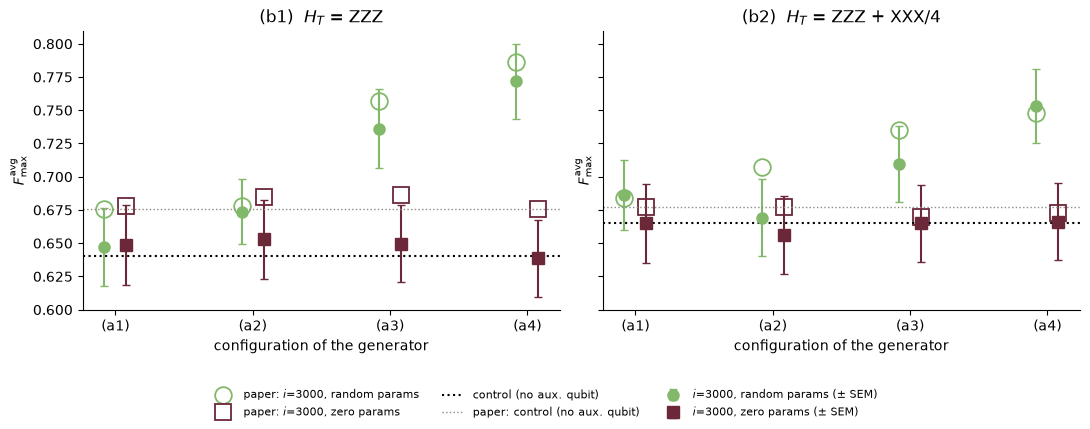

In [11]:
mid["ZZZ + XXX/4"] = run_experiment("mid_ZZZ_XXX", INSERTIONS, from_plateaus=True, **TARGETS["ZZZ + XXX/4"])
best_mid["ZZZ + XXX/4"] = plateau_best(mid["ZZZ + XXX/4"], INSERTIONS)
insertion_table(best_mid["ZZZ + XXX/4"], PAPER_MID["ZZZ + XXX/4"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
for ax, (tag, name) in zip(axes, [("(b1)", "ZZZ"), ("(b2)", "ZZZ + XXX/4")]):
    insertion_panel(ax, best_mid[name], PAPER_MID[name], f"{tag}  $H_T$ = {name}")
    ax.set_xlabel("configuration of the generator")
legend_below(fig, axes[0])
plt.show()

**What this shows** (Sec. III A–C, Fig. 2(b)):

- **Connectivity.** With random angles, the gain grows with the connectivity of the auxiliary qubit: little for
  (a1) and (a2), much more for (a3), which bridges the two distant ends of the chain, and most for (a4), coupled to
  every qubit. This is the order of the expressivities of the circuits, $\mathcal E_4 > \mathcal E_3 > \mathcal E_2 >
  \mathcal E_1$ (Sec. III A).
- **Randomisation.** With zero angles, the inserted gates start as the identity: the training continues from the
  same unitary, and the fidelity stays at the control's (Sec. III C).

One training, continued with (a4): the fidelity first drops, as the random gates scramble the learned unitary, and
then climbs above the plateau. (The zero-angle continuation stays close to the control, but need not coincide with
it: its gates start as the identity and are then trained, and the critic has a new random row for the auxiliary
qubit.)

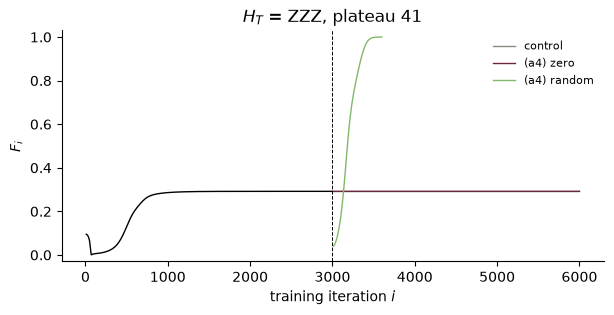

In [12]:
def show_insertion(plateau, labels, ax):
    # The fidelity of one plateau run: the first phase, then the control and the continuations of `labels`
    first = fidelity_record(plateau)
    it0 = 10 * np.arange(1, len(first) + 1)
    ax.plot(it0, first, color="black", lw=1)
    cont = {"control": plateau / "repeated_control"}
    cont.update({label: plateau / f"repeated_changed_run{list(INSERTIONS).index(label) + 1}" / "1" for label in labels})
    for (label, run), color in zip(cont.items(), ["#8c8b85", ZERO_COLOR, RANDOM_COLOR]):
        F = fidelity_record(run)
        ax.plot(it0[-1] + 10 * np.arange(1, len(F) + 1), F, color=color, lw=1, label=label)
    ax.axvline(it0[-1], color="black", ls="--", lw=0.7)
    ax.set(xlabel="training iteration $i$", ylabel="$F_i$", ylim=(-0.03, 1.03))
    ax.legend(frameon=False, fontsize=8)


# the plateau whose (a4) insertion gained most
gain = best_mid["ZZZ"]["(a4) random"] - best_mid["ZZZ"]["control"]
i = int(np.nanargmax(gain)) + 1
fig, ax = plt.subplots(figsize=(7, 3))
show_insertion(mid["ZZZ"] / f"initial_plateau_{i}", ["(a4) zero", "(a4) random"], ax)
ax.set_title(f"$H_T$ = ZZZ, plateau {i}")
plt.show()

## 3. Timing: the auxiliary qubit from the start

Is the gain only the larger expressivity of the bigger circuit? Sec. III B trains each configuration with the
auxiliary qubit present from the start, for the same 6000 iterations, against the circuit without it. In the
repository this is the *from scratch* mode of a multiple run, `CFG.common_initial_plateaus = False`: each entry of
`CFG.reps_new_config` is a setting, trained `CFG.N_reps_if_from_scratch` times from random angles and critics. Here
`epochs` doubles (6000 iterations with the settings of the saved outputs).

In [13]:
FROM_START = {"no aux. qubit": ARCHS["no aux. qubit"],
              **{f"{c} random": {**ARCHS[c], "start_ancilla_gates_randomly": True} for c in CONFIGS}}
start = {}
start["ZZZ"] = run_experiment("start_ZZZ", FROM_START, epochs=2 * ITERATIONS // 300, **TARGETS["ZZZ"])

start_ZZZ: reusing the results saved in generated_data/notebook/start_ZZZ/ (trained in 25.7 min)


In [14]:
start["ZZZ + XXX/4"] = run_experiment("start_ZZZ_XXX", FROM_START, epochs=2 * ITERATIONS // 300,
                                      **TARGETS["ZZZ + XXX/4"])


def scratch_best(folder, labels, n=N_RUNS):
    # {label: (n,) F_max of each training} of a from-scratch multiple run (experiment<j>/<repetition>/)
    return {label: np.array([best_fidelity(folder / f"experiment{j}" / str(r)) for r in range(1, n + 1)])
            for j, label in enumerate(labels, 1)}


# label: (F_avg_max, SEM), from the archived runs of Fig. 3 (100 trainings each)
PAPER_START = {
    "ZZZ": {"no aux. qubit": (0.652, 0.018), "(a1) random": (0.677, 0.021), "(a2) random": (0.666, 0.019),
            "(a3) random": (0.706, 0.022), "(a4) random": (0.710, 0.019)},
    "ZZZ + XXX/4": {"no aux. qubit": (0.650, 0.017), "(a1) random": (0.640, 0.016), "(a2) random": (0.676, 0.018),
                    "(a3) random": (0.696, 0.021), "(a4) random": (0.715, 0.016)},
}
best_start = {name: scratch_best(start[name], FROM_START) for name in start}
for name, best in best_start.items():
    print(f"H_T = {name}: F_avg_max after {2 * ITERATIONS} iterations from the start (paper)")
    ref = mean_sem(best["no aux. qubit"])[0]
    for label, values in best.items():
        (m, s), p = mean_sem(values), PAPER_START[name][label]
        print(f"   {label:14s} {m:.3f} ± {s:.3f}   gain {m - ref:+.3f}   ({p[0]:.3f} ± {p[1]:.3f})")

start_ZZZ_XXX: reusing the results saved in generated_data/notebook/start_ZZZ_XXX/ (trained in 29.1 min)


H_T = ZZZ: F_avg_max after 6000 iterations from the start (paper)
   no aux. qubit  0.673 ± 0.032   gain +0.000   (0.652 ± 0.018)
   (a1) random    0.707 ± 0.027   gain +0.034   (0.677 ± 0.021)
   (a2) random    0.691 ± 0.027   gain +0.018   (0.666 ± 0.019)
   (a3) random    0.758 ± 0.028   gain +0.085   (0.706 ± 0.022)
   (a4) random    0.711 ± 0.025   gain +0.038   (0.710 ± 0.019)
H_T = ZZZ + XXX/4: F_avg_max after 6000 iterations from the start (paper)
   no aux. qubit  0.665 ± 0.030   gain +0.000   (0.650 ± 0.017)
   (a1) random    0.701 ± 0.023   gain +0.036   (0.640 ± 0.016)
   (a2) random    0.698 ± 0.022   gain +0.033   (0.676 ± 0.018)
   (a3) random    0.706 ± 0.025   gain +0.041   (0.696 ± 0.021)
   (a4) random    0.719 ± 0.022   gain +0.054   (0.715 ± 0.016)


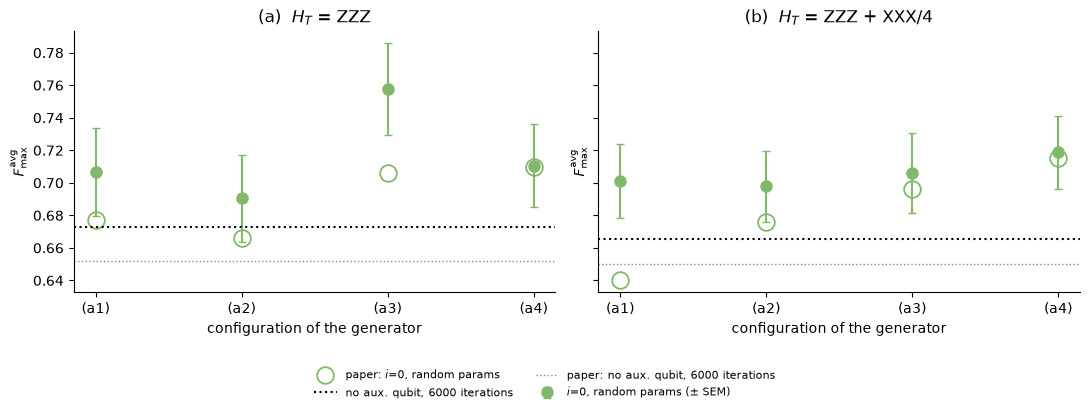

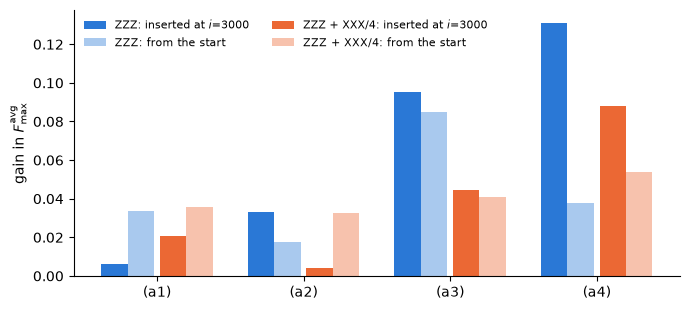

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1), sharey=True)
for ax, (tag, name) in zip(axes, [("(a)", "ZZZ"), ("(b)", "ZZZ + XXX/4")]):
    best = {"control": best_start[name]["no aux. qubit"], **best_start[name]}
    paper = {"control": PAPER_START[name]["no aux. qubit"], **PAPER_START[name]}
    insertion_panel(ax, best, paper, f"{tag}  $H_T$ = {name}", zero=False, when="$i$=0", paper_when="$i$=0",
                    control=f"no aux. qubit, {2 * ITERATIONS} iterations",
                    paper_control="no aux. qubit, 6000 iterations")
    ax.set_xlabel("configuration of the generator")
legend_below(fig, axes[0], ncol=2)
plt.show()

# The gains over the circuit without the auxiliary qubit: inserted at the plateau (§2) vs present from the start
fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(4)
for k, (name, color) in enumerate([("ZZZ", "#2a78d6"), ("ZZZ + XXX/4", "#eb6834")]):
    g_mid = [mean_sem(best_mid[name][f"{c} random"] - best_mid[name]["control"])[0] for c in CONFIGS]
    ref = mean_sem(best_start[name]["no aux. qubit"])[0]
    g_start = [mean_sem(best_start[name][f"{c} random"])[0] - ref for c in CONFIGS]
    ax.bar(x + 0.2 * (2 * k - 1) - 0.09, g_mid, 0.18, color=color, label=f"{name}: inserted at $i$={ITERATIONS}")
    ax.bar(x + 0.2 * (2 * k - 1) + 0.09, g_start, 0.18, color=color, alpha=0.4, label=f"{name}: from the start")
ax.axhline(0, color="black", lw=0.7)
ax.set_xticks(x, CONFIGS)
ax.set_ylabel("gain in $F^\\mathrm{avg}_\\mathrm{max}$")
ax.legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

**What this shows** (Sec. III B, Fig. 3). Present from the start, the auxiliary qubit still helps, by 0.02 to
0.09 in $F^{\mathrm{avg}}_{\max}$. But the configuration that helps most at the plateau, (a4), helps less from the start
(about +0.04 against +0.13 for $H_T = Z_1Z_2Z_3$, +0.05 against +0.09 with $X_1X_2X_3/4$), although the circuit and
the total number of iterations (6000) are the same: the timing matters, not
only the expressivity. The extra degrees of freedom help most when they appear where the optimisation stalls. For
(a1) and (a2), whose gains are small either way, the order of the two can reverse. (The from-start gains compare
independent trainings, so their errors are larger, about ±0.04, than those of the paired gains of §2.)

## 4. Entanglement during training

Sec. IV A follows the entanglement of the generator along a training: the von Neumann entropy $S(\rho_a)$ of the
auxiliary qubit (Eq. 9), and the negativity $\mathcal N(\rho_{ij})$ of every pair of qubits (Eq. 10). The pairwise
negativities cannot be read from the Choi state, whose reference half makes every system marginal maximally mixed.
They are averaged over 50 Haar-random product inputs, the auxiliary qubit in $|0\rangle$ (Appendix C).

The repository computes both with `CFG.compute_entanglement = True`, and writes
`fidelities/log_entropy.txt` and `fidelities/log_negativity_<ij>.txt`. Here: a few plateaus of $H_T = Z_1Z_2Z_3$,
continued with (a2) and with (a4), both with random angles.

In [16]:
ENT_ARMS = {c: {**ARCHS[c], "start_ancilla_gates_randomly": True} for c in ("(a2)", "(a4)")}
ent = run_experiment("entanglement_ZZZ", ENT_ARMS, from_plateaus=True, n_runs=N_ENTANGLEMENT, compute_entanglement=True,
                     **TARGETS["ZZZ"])
best_ent = plateau_best(ent, ENT_ARMS, n=N_ENTANGLEMENT)
for i in range(N_ENTANGLEMENT):
    print(f"plateau {i + 1}: F_max control {best_ent['control'][i]:.3f}, (a2) {best_ent['(a2)'][i]:.3f}, "
          f"(a4) {best_ent['(a4)'][i]:.3f}")

entanglement_ZZZ: reusing the results saved in generated_data/notebook/entanglement_ZZZ/ (trained in 24.0 min)
plateau 1: F_max control 0.476, (a2) 0.476, (a4) 0.476
plateau 2: F_max control 0.476, (a2) 0.477, (a4) 0.476
plateau 3: F_max control 1.000, (a2) 0.714, (a4) 0.714
plateau 4: F_max control 0.705, (a2) 0.708, (a4) 0.707
plateau 5: F_max control 0.984, (a2) 0.984, (a4) 0.993
plateau 6: F_max control 0.991, (a2) 0.990, (a4) 0.991
plateau 7: F_max control 0.477, (a2) 0.477, (a4) 0.708
plateau 8: F_max control 0.000, (a2) 0.000, (a4) 0.000
plateau 9: F_max control 0.477, (a2) 0.477, (a4) 0.477
plateau 10: F_max control 0.708, (a2) 0.708, (a4) 1.000
plateau 11: F_max control 0.708, (a2) 0.708, (a4) 0.955
plateau 12: F_max control 0.708, (a2) 0.708, (a4) 0.708
plateau 13: F_max control 0.500, (a2) 0.485, (a4) 0.955
plateau 14: F_max control 0.707, (a2) 0.708, (a4) 0.707
plateau 15: F_max control 0.945, (a2) 0.476, (a4) 0.708
plateau 16: F_max control 0.477, (a2) 0.477, (a4) 0.477
pl

plateau 13


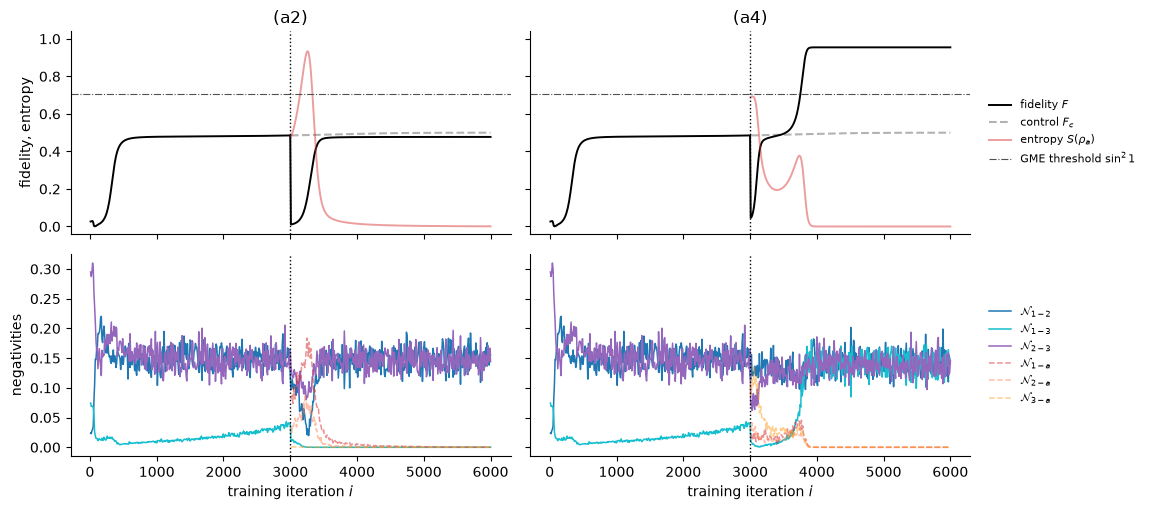

In [17]:
def record(run_dir, name):
    path = Path(run_dir) / "fidelities" / name
    return np.atleast_1d(np.loadtxt(path)) if path.exists() else np.array([])


NEG_COLORS = {"12": "#1f77b4", "13": "#17becf", "23": "#9467bd", "1a": "#d62728", "2a": "#ff7f50", "3a": "#ff9f1c"}


def entanglement_figure(plateau, labels):
    # Fig. 5: fidelity, control and entropy (top), pairwise negativities (bottom), before and after the insertion
    first = fidelity_record(plateau)
    n0 = len(first)
    it0 = 10 * np.arange(1, n0 + 1)
    control = fidelity_record(plateau / "repeated_control")
    fig, axes = plt.subplots(2, len(labels), figsize=(11.5, 5.2), sharex=True, sharey="row")
    for col, label in enumerate(labels):
        run = plateau / f"repeated_changed_run{list(ENT_ARMS).index(label) + 1}" / "1"
        F = fidelity_record(run)
        it1 = it0[-1] + 10 * np.arange(1, len(F) + 1)
        top, bottom = axes[0, col], axes[1, col]
        top.plot(np.r_[it0, it1], np.r_[first, F], color="black", lw=1.4, label="fidelity $F$")
        top.plot(it0[-1] + 10 * np.arange(1, len(control) + 1), control, color="black", ls="--", alpha=0.3,
                 label="control $F_c$")
        S = record(run, "log_entropy.txt")
        top.plot(it1[: len(S)], S[: len(it1)], color="#d62728", alpha=0.45, lw=1.4, label=r"entropy $S(\rho_a)$")
        top.axhline(np.sin(1) ** 2, color="#52514e", ls="-.", lw=0.8, label=r"GME threshold $\sin^2 1$")
        top.set(title=label, ylim=(-0.04, 1.04))
        for pair, color in NEG_COLORS.items():
            before = record(plateau, f"log_negativity_{pair}.txt") if "a" not in pair else np.array([])
            after = record(run, f"log_negativity_{pair}.txt")
            values = np.r_[before, after]
            its = np.r_[it0[: len(before)], it1[: len(after)]]
            bottom.plot(its, values[: len(its)], color=color, ls="--" if "a" in pair else "-", lw=1.1,
                        alpha=0.5 if "a" in pair else 1, label=f"$\\mathcal{{N}}_{{{pair[0]}-{pair[1]}}}$")
        for ax in (top, bottom):
            ax.axvline(it0[-1], color="black", ls=":", lw=1)
        bottom.set_xlabel("training iteration $i$")
    axes[0, 0].set_ylabel("fidelity, entropy")
    axes[1, 0].set_ylabel("negativities")
    axes[0, -1].legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1.02, 0.5))
    axes[1, -1].legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1.02, 0.5))
    plt.tight_layout()
    plt.show()


# The example: a plateau that the control does not leave, where (a4) gains most over (a2)
plateau_F = np.array([fidelity_record(ent / f"initial_plateau_{i}").max() for i in range(1, N_ENTANGLEMENT + 1)])
stuck = best_ent["control"] < plateau_F + 0.02
i = int(np.argmax(np.where(stuck, best_ent["(a4)"] - best_ent["(a2)"], -np.inf) if stuck.any()
                  else best_ent["(a4)"] - best_ent["(a2)"])) + 1
print(f"plateau {i}")
entanglement_figure(ent / f"initial_plateau_{i}", list(ENT_ARMS))

In [18]:
# Over all plateaus of this section: the negativity of the distant pair 1-3 on the plateau and at the end of training,
# the entropy of the auxiliary qubit at the end, and how many trainings certify GME with a margin (see the text below)
GME = np.sin(1) ** 2 + 0.01
for label in ENT_ARMS:
    j = list(ENT_ARMS).index(label) + 1
    n13_plateau, n13_end, s_end = [], [], []
    for i in range(1, N_ENTANGLEMENT + 1):
        plateau = ent / f"initial_plateau_{i}"
        run = plateau / f"repeated_changed_run{j}" / "1"
        n13_plateau.append(record(plateau, "log_negativity_13.txt")[-10:].mean())
        n13_end.append(record(run, "log_negativity_13.txt")[-10:].mean())
        s_end.append(record(run, "log_entropy.txt")[-10:].mean())
    print(f"{label}: N_1-3 on the plateau {np.mean(n13_plateau):.3f} -> at the end {np.mean(n13_end):.3f};  "
          f"S(rho_a) at the end {np.mean(s_end):.3f};  F_max > sin^2(1) + 0.01 in {np.sum(best_ent[label] > GME)} "
          f"of {N_ENTANGLEMENT} trainings")
print(f"control: F_max > sin^2(1) + 0.01 in {np.sum(best_ent['control'] > GME)} of {N_ENTANGLEMENT} trainings")

(a2): N_1-3 on the plateau 0.022 -> at the end 0.011;  S(rho_a) at the end 0.021;  F_max > sin^2(1) + 0.01 in 3 of 24 trainings
(a4): N_1-3 on the plateau 0.022 -> at the end 0.039;  S(rho_a) at the end 0.083;  F_max > sin^2(1) + 0.01 in 6 of 24 trainings
control: F_max > sin^2(1) + 0.01 in 5 of 24 trainings


**What this shows** (Sec. IV A, Fig. 5). On the plateau, the entanglement of the generator is uneven: the
distant pair 1–3 is barely entangled. The insertion makes $S(\rho_a)$ jump: the auxiliary qubit becomes entangled with
the system. With (a2) this changes little in the system and the training stays on its plateau. With (a4) the pairwise
entanglement reorganises, the pair 1–3 catches up with the others, and the fidelity leaves the plateau, crossing the
GME threshold $\sin^2 1 \approx 0.708$ of the target. At the end of a training that converges, the auxiliary qubit
decouples again ($S \to 0$: at $F = 1$ the generator is block diagonal, Fig. 1(c)).

Over all the plateaus of this section (the printout above), the negativity of the distant pair 1–3 grows with (a4)
(0.022 → 0.039) and falls with (a2) (0.022 → 0.011). Many plateaus sit at $F=\sin^2 1$ itself: there the generator
has learned $Z\otimes Z\otimes Z$, a product of single-qubit gates, which reaches exactly the bound. Certifying GME
therefore needs a margin: $F_{\max}>\sin^2 1+0.01$ holds for 6 of the 24 trainings with (a4), 3 with (a2) and 5 for
the control. With so few trainings, the difference shows in the negativities more than in these counts. Not every
plateau is left: many trainings stay where they are with both configurations.

## 5. Gradients at the insertion

Sec. IV B compares the gradients $|\partial W/\partial\theta_k|$ of the cost with respect to the system's angles
right at the insertion ($i = 3000$) and 500 iterations later, with and without the auxiliary qubit, over many
plateaus.

Here we take the plateaus of $H_T = Z_1Z_2Z_3$ from §2 and use the code's own training steps. For each
configuration, every plateau is loaded with the auxiliary qubit inserted (random angles, a new random critic row),
exactly as §2 continues it: a `Training()` and `load_models_if_specified()` with `CFG.load_timestamp` set to the
plateau. The gradient is the generator's analytic gradient, `gen._grad_theta()` (no update), and the run is then
trained for `GRADIENT_ITERATIONS` iterations (`dis.update_dis()` and `gen.update_gen()`, one each per iteration). As in
the paper's gradient study, the optimiser momentum restarts at the insertion; the NumPy code of this branch computes in
double precision.

In [19]:
GRAD_ARMS = {"no aux. qubit": ARCHS["no aux. qubit"],
             **{c: {**ARCHS[c], "start_ancilla_gates_randomly": True} for c in CONFIGS}}


def system_angles(gen):
    # The indices of the generator's gates that act on the system only (not on the auxiliary qubit)
    if not CFG.extra_ancilla:
        return list(range(len(gen.qc.gates)))
    return [k for k, g in enumerate(gen.qc.gates) if CFG.system_size not in (g.qubit1, g.qubit2)]


def insertion_gradients(plateau_folder, n, iterations=GRADIENT_ITERATIONS):
    # {label: dict(g0, g1: (n, 24) |dW/dtheta_k| of the system angles at the insertion and `iterations` later, F0, F1)}
    folder = Path("generated_data") / RESULTS / "gradients_ZZZ"
    file = folder / "gradients.npz"
    signature = json.dumps(dict(plateaus=str(plateau_folder), n=n, iterations=iterations, seed=SEED,
                                arms=GRAD_ARMS, base_iterations=ITERATIONS))
    if not RERUN and file.exists() and (folder / "notebook_signature.json").read_text() == signature:
        print(f"reusing {file}")
        with np.load(file) as data:
            return {label: {key: data[f"{label}|{key}"] for key in ("g0", "g1", "F0", "F1")} for label in GRAD_ARMS}
    shutil.rmtree(folder, ignore_errors=True)
    (folder / "logs").mkdir(parents=True)
    out = {}
    for label, arm in GRAD_ARMS.items():
        t0 = time.time()
        configure(**arm, **TARGETS["ZZZ"], run_timestamp=f"{RESULTS}/gradients_ZZZ", run_multiple_experiments=False)
        np.random.seed(SEED)
        g0, g1, F0, F1 = [], [], [], []
        with open(folder / "logs" / "loading.txt", "a") as log, contextlib.redirect_stdout(log):
            for i in range(1, n + 1):
                CFG.load_timestamp = str(Path(*plateau_folder.parts[1:]) / f"initial_plateau_{i}")
                run = Training()
                load_models_if_specified(run)  # the plateau, with the auxiliary qubit inserted
                gen, dis, target = run.gen, run.dis, run.final_target_state
                system = system_angles(gen)
                g0.append(gen._grad_theta(dis, target, gen.total_gen_state)[system])
                F0.append(compute_fidelity(target, gen.total_gen_state))
                for _ in range(iterations):
                    dis.update_dis(target, gen.total_gen_state)
                    gen.update_gen(dis, target)
                g1.append(gen._grad_theta(dis, target, gen.total_gen_state)[system])
                F1.append(compute_fidelity(target, gen.total_gen_state))
        out[label] = dict(g0=np.abs(np.array(g0)), g1=np.abs(np.array(g1)), F0=np.array(F0), F1=np.array(F1))
        print(f"{label:14s} {n} plateaus, {len(system)} system angles: {time.time() - t0:.0f} s")
    np.savez(file, **{f"{label}|{key}": v for label, d in out.items() for key, v in d.items()})
    (folder / "notebook_signature.json").write_text(signature)
    return out


grads = insertion_gradients(mid["ZZZ"], N_RUNS)

reusing generated_data/notebook/gradients_ZZZ/gradients.npz


                median |dW/dθ| at i=3000     at i=3500   |  paper          |  mean F at i=3000, later
no aux. qubit                   5.68e-05      3.54e-05   |  2.66e-05 1.56e-05  |  0.576, 0.569
(a1)                            1.73e-03      1.01e-04   |  1.69e-03 7.65e-05  |  0.143, 0.548
(a2)                            2.66e-03      3.48e-04   |  2.81e-03 2.66e-04  |  0.043, 0.544
(a3)                            2.88e-03      3.02e-04   |  2.87e-03 2.18e-04  |  0.045, 0.565
(a4)                            2.62e-03      5.18e-04   |  2.83e-03 6.22e-04  |  0.022, 0.475


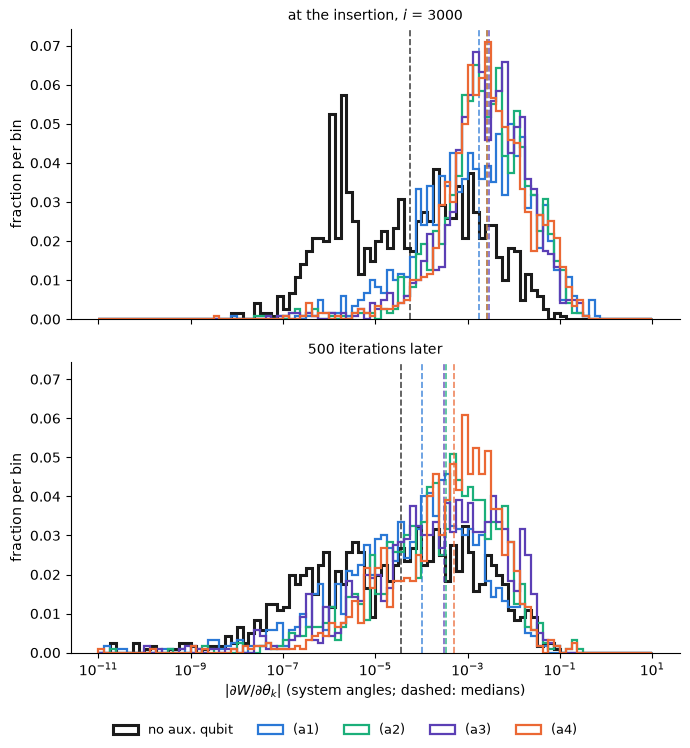

In [20]:
# The medians of |dW/dtheta_k| over the system angles of Fig. 6: at the insertion, 500 iterations later
PAPER_GRAD = {"no aux. qubit": (2.66e-5, 1.56e-5), "(a1)": (1.69e-3, 7.65e-5), "(a2)": (2.81e-3, 2.66e-4),
              "(a3)": (2.87e-3, 2.18e-4), "(a4)": (2.83e-3, 6.22e-4)}
GRAD_COLORS = {"no aux. qubit": "#1b1b1b", "(a1)": "#2a78d6", "(a2)": "#1baf7a", "(a3)": "#5b3fb5", "(a4)": "#eb6834"}

print(f"{'':14s}{f'median |dW/dθ| at i={ITERATIONS}':>26s}{f'at i={ITERATIONS + GRADIENT_ITERATIONS}':>14s}   |  paper"
      f"          |  mean F at i={ITERATIONS}, later")
for label, d in grads.items():
    p = PAPER_GRAD[label]
    print(f"{label:14s}{np.median(d['g0']):>26.2e}{np.median(d['g1']):>14.2e}   |  {p[0]:.2e} {p[1]:.2e}"
          f"  |  {d['F0'].mean():.3f}, {d['F1'].mean():.3f}")

bins = np.logspace(-11, 1, 97)
fig, axes = plt.subplots(2, 1, figsize=(7, 7.5), sharex=True, sharey=True)
for ax, key, when in ((axes[0], "g0", f"at the insertion, $i$ = {ITERATIONS}"),
                      (axes[1], "g1", f"{GRADIENT_ITERATIONS} iterations later")):
    for label, d in grads.items():
        values = d[key].ravel()
        values = values[values > 0]
        weights = np.full(len(values), 1 / len(values))
        ax.hist(values, bins=bins, weights=weights, histtype="step", lw=2.2 if label == "no aux. qubit" else 1.6,
                color=GRAD_COLORS[label], label=label)
        ax.axvline(np.median(values), color=GRAD_COLORS[label], ls="--", lw=1.2, alpha=0.8)
    ax.set_xscale("log")
    ax.set_ylabel("fraction per bin")
    ax.set_title(when, fontsize=10)
axes[1].set_xlabel(r"$|\partial W/\partial\theta_k|$ (system angles; dashed: medians)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=5, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

**What this shows** (Sec. IV B, Fig. 6). On the plateau, without the auxiliary qubit, most gradients are tiny
(the bimodal black histogram, its median a few $10^{-5}$). The insertion raises them by one and a half to two
orders of magnitude, by a similar amount for (a2)–(a4) and a little less for (a1). 500
iterations later the gradients have contracted again, but not equally: (a4) keeps the largest, (a1) the smallest,
and (a2) and (a3) cannot be told apart from the histograms alone.

## 6. Four system qubits (optional)

Appendix D repeats the insertion protocol of §2 for four system qubits, $H_T = Z_1Z_2Z_3 + Z_2Z_3Z_4$ (in `CFG`,
`"ZZZ"` is summed over every window of three neighbours) with seven layers. It is the slowest experiment,
by far on this branch: set `RUN_N4 = True` in the first cell to run it. Without it, the cell draws the paper's values only.

Skipped (RUN_N4 = False): the paper's values only.


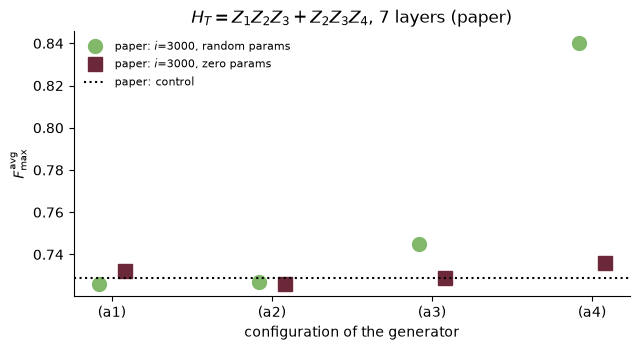

In [21]:
PAPER_N4 = {"control": (0.729, 0, 0),  # 99 plateaus, from the archived runs of Fig. 8
            "(a1) random": (0.726, -0.0029, 0.0063), "(a2) random": (0.727, -0.0021, 0.0118),
            "(a3) random": (0.745, 0.0157, 0.0094), "(a4) random": (0.840, 0.1110, 0.0198),
            "(a1) zero": (0.732, 0.0026, 0.0057), "(a2) zero": (0.726, -0.0026, 0.0045),
            "(a3) zero": (0.729, -0.0002, 0.0051), "(a4) zero": (0.736, 0.0072, 0.0054)}
N4 = dict(system_size=4, gen_layers=7, **TARGETS["ZZZ"])

fig, ax = plt.subplots(figsize=(6.5, 3.6))
if RUN_N4:
    mid["N=4"] = run_experiment("mid_N4", INSERTIONS, from_plateaus=True, **N4)
    best_mid["N=4"] = plateau_best(mid["N=4"], INSERTIONS)
    insertion_table(best_mid["N=4"], PAPER_N4)
    insertion_panel(ax, best_mid["N=4"], PAPER_N4, "$H_T = Z_1Z_2Z_3 + Z_2Z_3Z_4$, 7 layers")
    ax.legend(frameon=False, fontsize=7, loc="upper left")
else:
    print("Skipped (RUN_N4 = False): the paper's values only.")
    x = np.arange(4)
    for k, (init, color, marker) in enumerate([("random", RANDOM_COLOR, "o"), ("zero", ZERO_COLOR, "s")]):
        ax.plot(x + 0.08 * (2 * k - 1), [PAPER_N4[f"{c} {init}"][0] for c in CONFIGS], ls="none", marker=marker,
                ms=10, color=color, label=f"paper: $i$=3000, {init} params")
    ax.axhline(PAPER_N4["control"][0], color="black", ls=":", label="paper: control")
    ax.set_xticks(x, CONFIGS)
    ax.set(ylabel=r"$F^\mathrm{avg}_\mathrm{max}$", title="$H_T = Z_1Z_2Z_3 + Z_2Z_3Z_4$, 7 layers (paper)")
    ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_xlabel("configuration of the generator")
plt.tight_layout()
plt.show()

With four qubits only the fully connected auxiliary qubit (a4) still gives a clear gain; (a3), which bridges only the
two ends of a longer chain, gives much less (Appendix D).

## 7. Where to go from here

**The paper's other results and the `CFG` options behind them.**

| Paper | How, in `src/` |
|---|---|
| Randomised restart without auxiliary qubit, Fig. 4 (Sec. III C) | the plateau protocol of §2 with `reps_new_config` entries `{"type_of_warm_start": "some", "warm_start_strength": r}`: the fraction `r` of the angles re-drawn at random at the insertion (`"all"`: uniform noise of width `warm_start_strength`·2π on every angle) |
| Fidelity and cost along a training (cf. Fig. 5, top) and plots of every run | the `figures/` of each run; `src/replot.py` for the summary plots of a saved multiple run |
| Expressivity from the Jacobian rank, Fig. 7 (Appendix B) | not in `src/`: the Jacobian of the generator's state with respect to its angles (for instance, finite differences of `Generator.get_total_gen_state()`) and its rank at several tolerances |
| Other Hamiltonians, times and depths | `custom_hamiltonian_terms` / `custom_hamiltonian_strengths`, `target_hamiltonian="ising_h"` or `"cluster_h"`, `time_to_evolve`, `gen_layers` |

**Running the same experiments from the command line.** Copy the settings into the `Config` class of
`src/config.py` and run `python src/main.py` from the repository root. For example, Fig. 2(b1) is the base
configuration above with `run_multiple_experiments=True`, `common_initial_plateaus=True`, `N_initial_plateaus=100`,
`N_reps_each_init_plateau=1`, and `reps_new_config` = the eight dictionaries printed below.

In [22]:
# The insertions of section 2, ready to paste into reps_new_config of src/config.py
for label, changes in INSERTIONS.items():
    print(f"{changes},  # {label}")

{'extra_ancilla': True, 'ancilla_topology': 'ansatz', 'ancilla_connect_to': None, 'start_ancilla_gates_randomly': True},  # (a1) random
{'extra_ancilla': True, 'ancilla_topology': 'bridge', 'ancilla_connect_to': 1, 'start_ancilla_gates_randomly': True},  # (a2) random
{'extra_ancilla': True, 'ancilla_topology': 'bridge', 'ancilla_connect_to': None, 'start_ancilla_gates_randomly': True},  # (a3) random
{'extra_ancilla': True, 'ancilla_topology': 'total', 'ancilla_connect_to': None, 'start_ancilla_gates_randomly': True},  # (a4) random
{'extra_ancilla': True, 'ancilla_topology': 'ansatz', 'ancilla_connect_to': None, 'start_ancilla_gates_randomly': False},  # (a1) zero
{'extra_ancilla': True, 'ancilla_topology': 'bridge', 'ancilla_connect_to': 1, 'start_ancilla_gates_randomly': False},  # (a2) zero
{'extra_ancilla': True, 'ancilla_topology': 'bridge', 'ancilla_connect_to': None, 'start_ancilla_gates_randomly': False},  # (a3) zero
{'extra_ancilla': True, 'ancilla_topology': 'total', 'anci